# Synthetic eight experiment: multiscale alpha-neighboring graph

This notebook recreates the synthetic `eight` experiment described in `Reports/For_poster_COVID_case_Synthetic_Eight.pdf`.

The data are noisy samples from a two-dimensional eight-shaped curve. The graph construction follows the multiscale alpha-neighboring graph idea:

1. Use Euclidean distance on the original point cloud.
2. Use the first principal component as the projection/filter.
3. Cover the projected data by overlapping intervals.
4. In every cover element, select a local threshold alpha_i spectrally from the functional
   \[
   f(K_\alpha)=|C(K_\alpha)|\,|E(K_\alpha)|,
   \]
   where |C| is the number of connected components and |E| is the number of graph edges.
5. Connect two points in the same cover element if their Euclidean distance is at most 2 alpha_i. If a pair occurs in several cover elements, the largest available local threshold is used.

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances

plt.style.use("seaborn-v0_8-whitegrid")
RNG = np.random.default_rng(20260625)
SCALE_MATRIX_OPERATION = "union"

## 1. Sample a noisy eight

The clean curve is the Gerono lemniscate
\[
 x(t)=\sin(t), \qquad y(t)=\sin(t)\cos(t), \qquad t\in[0,2\pi),
\]
with small isotropic Gaussian noise added to each sampled point.

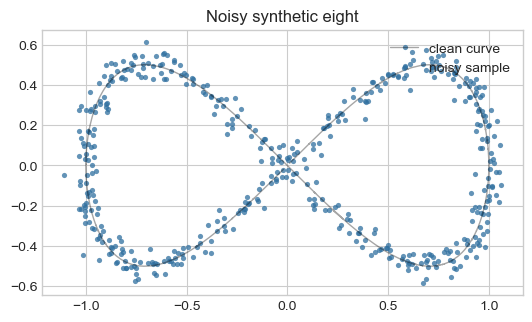

In [41]:
def sample_noisy_eight(n_points=480, noise_sd=0.035, rng=RNG):
    """Sample a noisy Gerono lemniscate."""
    t = np.linspace(0, 2 * np.pi, n_points, endpoint=False)
    t += rng.normal(0.0, 0.01, size=n_points)
    clean = np.column_stack([np.sin(t), np.sin(t) * np.cos(t)])
    noisy = clean + rng.normal(0.0, noise_sd, size=clean.shape)
    return noisy, clean, t

X, X_clean, t = sample_noisy_eight()

fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.plot(X_clean[:, 0], X_clean[:, 1], color="black", linewidth=1.0, alpha=0.35, label="clean curve")
ax.scatter(X[:, 0], X[:, 1], s=14, color="#2f6f9f", alpha=0.75, linewidths=0, label="noisy sample")
ax.set_title("Noisy synthetic eight")
ax.set_aspect("equal")
ax.legend(loc="upper right")
plt.show()

## 2. Spectral local scale selection

For one local subset, we sweep candidate values of alpha. At each candidate alpha we build the graph with edges
\[
 d(x_u,x_v)\le 2\alpha,
\]
compute `c_alpha = |C|*|E|`, and assemble the union version of the filtration scale matrix
\[
\Sigma_{ij}=c_{\max(i,j)}.
\]
This matches the poster methodology with \(K_i\oplus K_j=K_i\cup K_j=K_{\max(i,j)}\). The selected local scale is the candidate alpha where the Perron-Frobenius eigenvector has its largest entry.

In [42]:
def graph_counts_from_distance_matrix(D, alpha):
    """Return number of connected components and edges for threshold 2*alpha."""
    n = D.shape[0]
    adjacency = (D <= 2.0 * alpha) & (D > 0.0)
    edge_count = int(np.count_nonzero(np.triu(adjacency, 1)))

    if n == 0:
        return 0, 0
    if edge_count == 0:
        return n, 0

    graph = nx.from_numpy_array(adjacency)
    component_count = nx.number_connected_components(graph)
    return component_count, edge_count


def candidate_alphas(D, n_candidates=45, lower_q=0.02, upper_q=0.75):
    """Build a robust local alpha grid from local pairwise distances.

    The last candidate is 0.5 times the upper_q empirical distance quantile,
    not 0.5 times the local diameter. Use upper_q=1.0 for 0.5*diam(X_i).
    """
    positive_distances = D[np.triu_indices_from(D, k=1)]
    positive_distances = positive_distances[positive_distances > 0]
    if len(positive_distances) == 0:
        return np.array([0.0])

    lo, hi = np.quantile(positive_distances, [lower_q, upper_q]) / 2.0
    if np.isclose(lo, hi):
        hi = positive_distances.max() / 2.0
    return np.linspace(lo, hi, n_candidates)


def scale_similarity_matrix(c_values, operation="union", positivity=1e-10):
    """Construct Sigma from a filtration using either union/max or intersection/min."""
    c = np.asarray(c_values, dtype=float)
    c = np.maximum(c, 0.0) + positivity
    if operation == "union":
        idx = np.maximum.outer(np.arange(len(c)), np.arange(len(c)))
    elif operation == "intersection":
        idx = np.minimum.outer(np.arange(len(c)), np.arange(len(c)))
    else:
        raise ValueError("operation must be 'union' or 'intersection'")
    return c[idx]


def principal_pf_vector(Sigma):
    """Principal eigenpair for a symmetric nonnegative matrix."""
    eigenvalues, eigenvectors = np.linalg.eigh(Sigma)
    idx = int(np.argmax(eigenvalues))
    vector = np.abs(eigenvectors[:, idx])
    vector /= vector.sum()
    return float(eigenvalues[idx]), vector


def select_local_alpha(points, n_candidates=45, operation=SCALE_MATRIX_OPERATION):
    """Select alpha by the principal eigenvector of the |C|*|E| scale matrix."""
    n = len(points)
    if n < 3:
        return {
            "alpha": 0.0,
            "alphas": np.array([0.0]),
            "components": np.array([n]),
            "edges": np.array([0]),
            "functional": np.array([0.0]),
            "pf_vector": np.array([1.0]),
            "selected_index": 0,
            "alpha_min": 0.0,
            "alpha_max": 0.0,
        }

    D = pairwise_distances(points)
    alphas = candidate_alphas(D, n_candidates=n_candidates)
    counts = np.array([graph_counts_from_distance_matrix(D, alpha) for alpha in alphas])
    components = counts[:, 0]
    edges = counts[:, 1]
    functional = components * edges

    Sigma = scale_similarity_matrix(functional, operation=operation)
    _, pf_vector = principal_pf_vector(Sigma)
    selected_index = int(np.argmax(pf_vector))

    return {
        "alpha": float(alphas[selected_index]),
        "alphas": alphas,
        "components": components,
        "edges": edges,
        "functional": functional,
        "pf_vector": pf_vector,
        "selected_index": selected_index,
        "alpha_min": float(alphas[0]),
        "alpha_max": float(alphas[-1]),
    }

## 3. PCA cover

The cover is built on the first principal component. The overlap is intentional: it gives neighboring cover elements a shared boundary region, which is where the local alpha values are reconciled by taking the maximum applicable local threshold.

In [43]:
def overlapping_interval_cover(values, n_intervals=12, overlap_fraction=0.50):
    """Return overlapping intervals covering one-dimensional filter values."""
    lo, hi = float(values.min()), float(values.max())
    width = (hi - lo) / (n_intervals - (n_intervals - 1) * overlap_fraction)
    step = width * (1.0 - overlap_fraction)

    intervals = []
    for i in range(n_intervals):
        start = lo + i * step
        end = start + width
        if i == 0:
            start -= 1e-9
        if i == n_intervals - 1:
            end = hi + 1e-9
        intervals.append((start, end))
    return intervals

pca = PCA(n_components=1)
filter_values = pca.fit_transform(X).ravel()
cover = overlapping_interval_cover(filter_values, n_intervals=12, overlap_fraction=0.50)
cover_members = [np.flatnonzero((filter_values >= a) & (filter_values <= b)) for a, b in cover]

print(f"Explained variance by PC1: {pca.explained_variance_ratio_[0]:.3f}")
print(f"Cover elements: {len(cover)}")
print(f"Local subset sizes: min={min(map(len, cover_members))}, median={np.median(list(map(len, cover_members))):.0f}, max={max(map(len, cover_members))}")

Explained variance by PC1: 0.801
Cover elements: 12
Local subset sizes: min=48, median=62, max=112


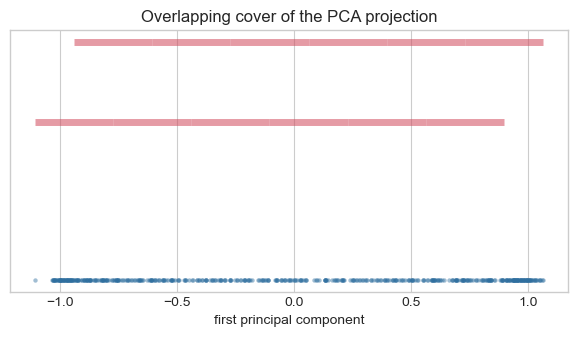

In [44]:
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.scatter(filter_values, np.zeros_like(filter_values), s=10, color="#2f6f9f", alpha=0.45, linewidths=0)
for j, (a, b) in enumerate(cover):
    y = 0.08 + 0.04 * (j % 2)
    ax.plot([a, b], [y, y], linewidth=5, solid_capstyle="butt", color="#d1495b", alpha=0.55)
ax.set_yticks([])
ax.set_xlabel("first principal component")
ax.set_title("Overlapping cover of the PCA projection")
plt.show()

## 4. Select local thresholds

Each row below is one cover element. The selected alpha is the local scale at which the principal eigenvector of the scale matrix is maximal.

In [45]:
local_results = []
for j, members in enumerate(cover_members):
    result = select_local_alpha(X[members], n_candidates=45)
    result["interval"] = cover[j]
    result["members"] = members
    local_results.append(result)

summary_rows = []
for j, result in enumerate(local_results):
    k = result["selected_index"]
    summary_rows.append((
        j,
        len(result["members"]),
        result["alpha"],
        int(result["components"][k]),
        int(result["edges"][k]),
        int(result["functional"][k]),
    ))

print("cover  size  alpha     |C|   |E|   |C|*|E|")
for row in summary_rows:
    print(f"{row[0]:>5} {row[1]:>5} {row[2]:>7.4f} {row[3]:>5} {row[4]:>5} {row[5]:>8}")

cover  size  alpha     |C|   |E|   |C|*|E|
    0   103  0.2973     1  3940     3940
    1    88  0.2103     2  1896     3792
    2    67  0.1759     2  1091     2182
    3    57  0.1892     2   758     1516
    4    55  0.2656     1  1114     1114
    5    54  0.1505     1  1073     1073
    6    51  0.1370     1   956      956
    7    48  0.2395     1   846      846
    8    54  0.1915     2   700     1400
    9    67  0.1977     2  1089     2178
   10    75  0.2041     2  1371     2742
   11   112  0.3152     1  4662     4662


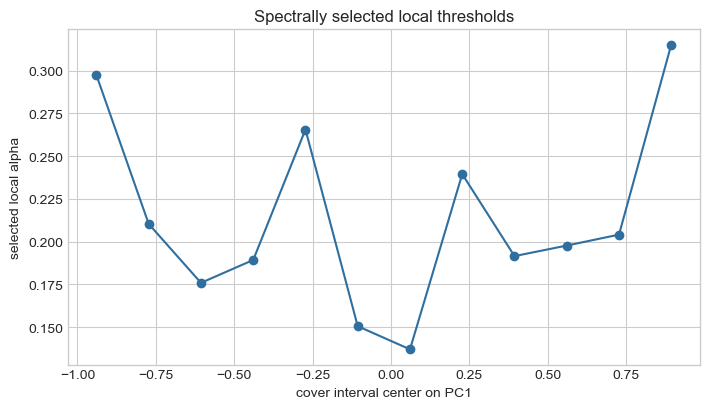

In [46]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))

selected_alphas = np.array([result["alpha"] for result in local_results])
cover_centers = np.array([(a + b) / 2 for a, b in cover])
ax.plot(cover_centers, selected_alphas, marker="o", color="#2f6f9f")
ax.set_xlabel("cover interval center on PC1")
ax.set_ylabel("selected local alpha")
ax.set_title("Spectrally selected local thresholds")

plt.tight_layout()
plt.show()

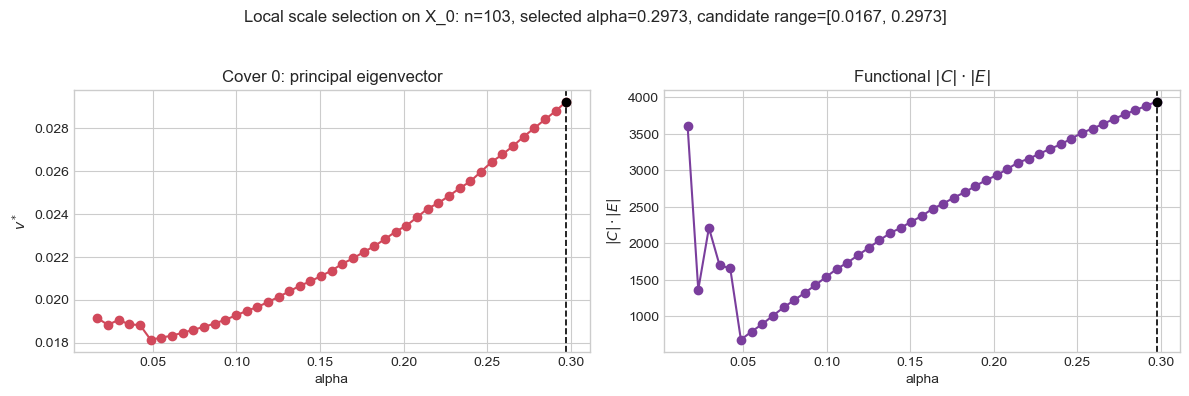

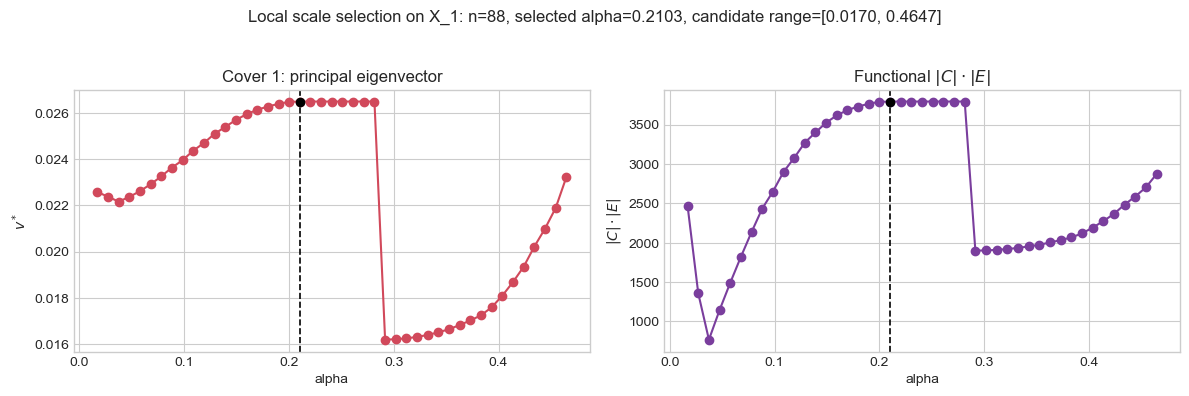

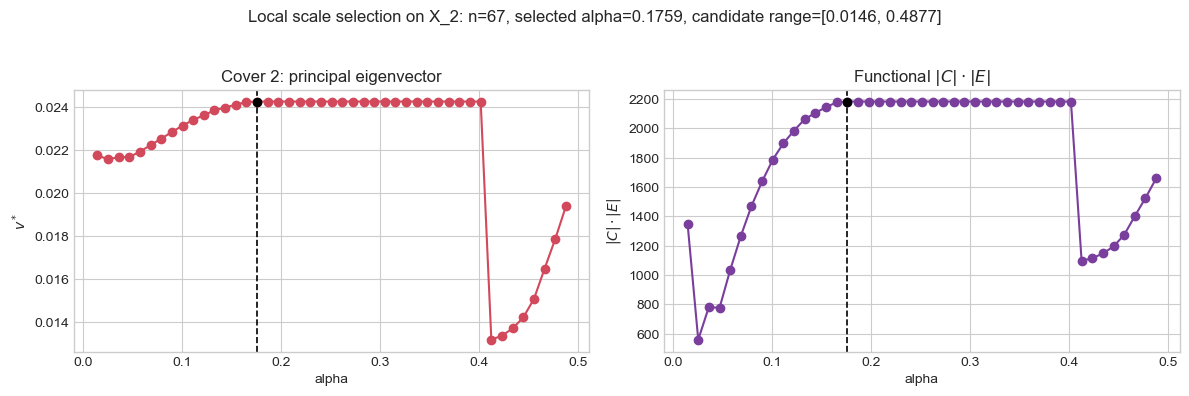

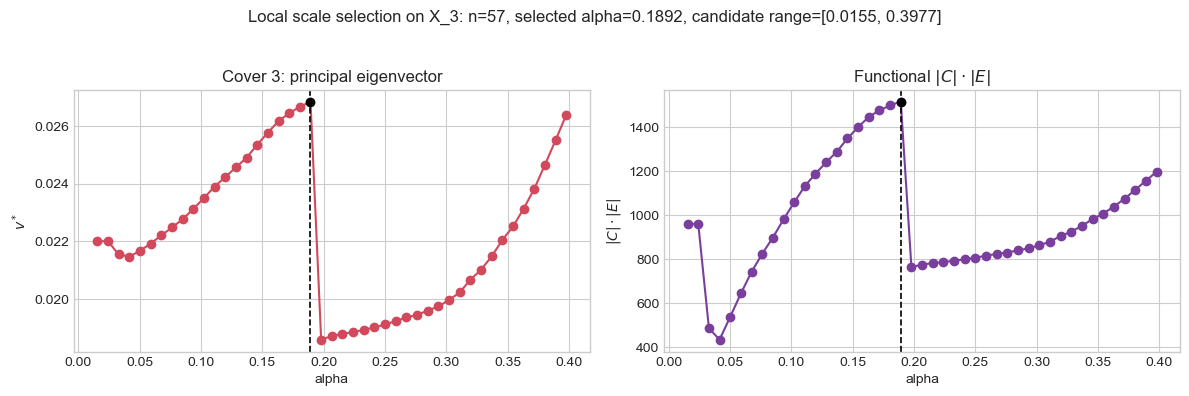

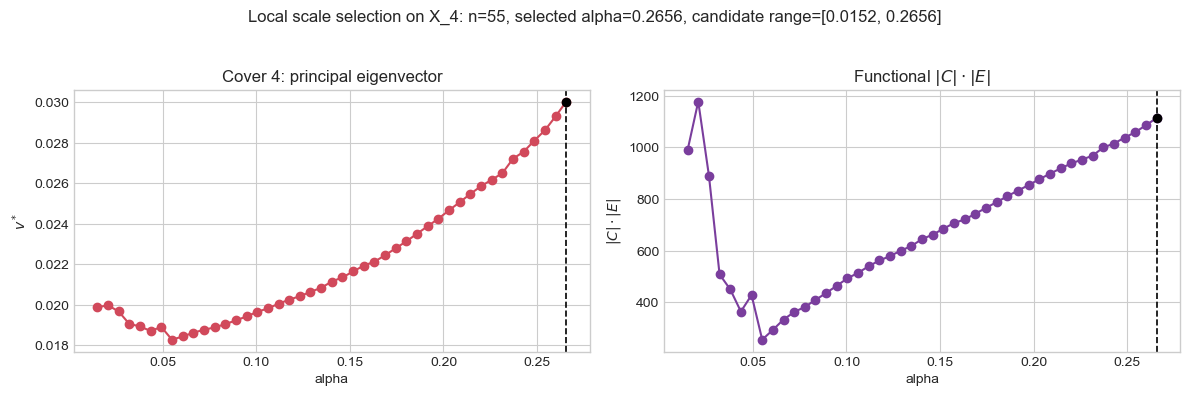

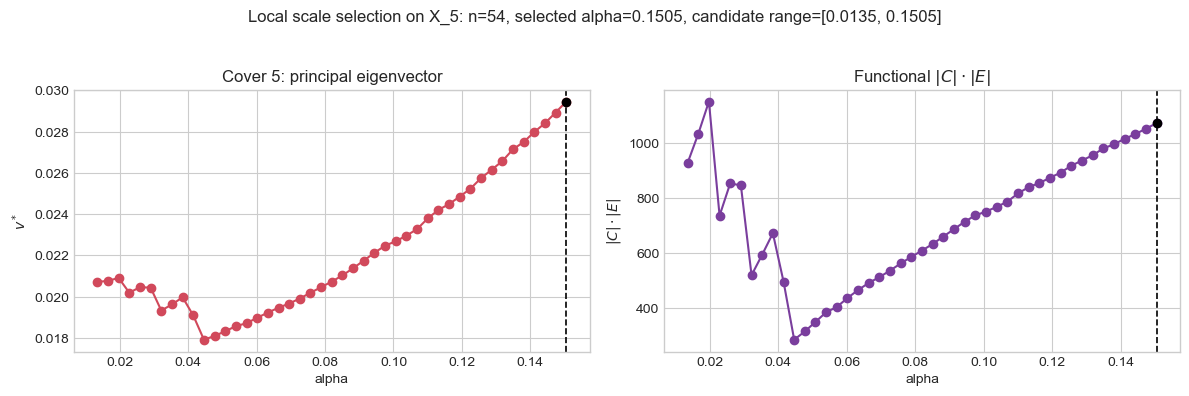

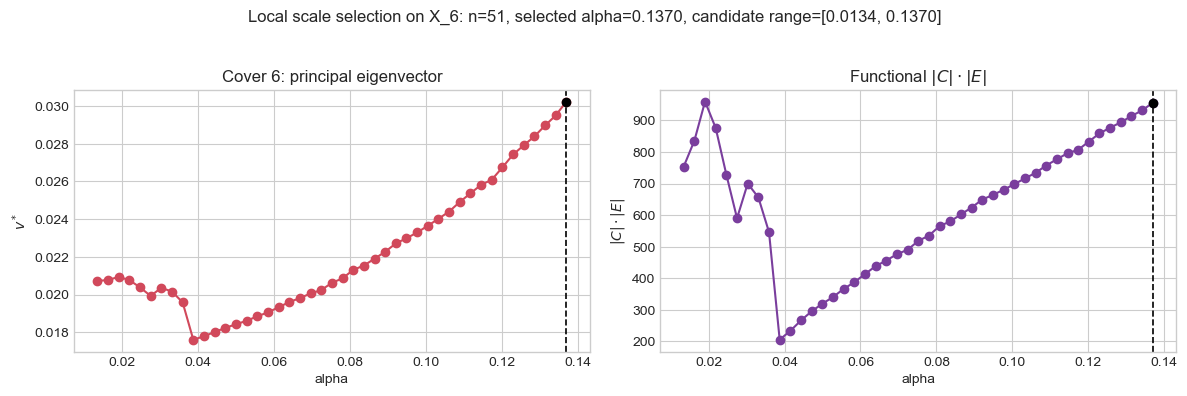

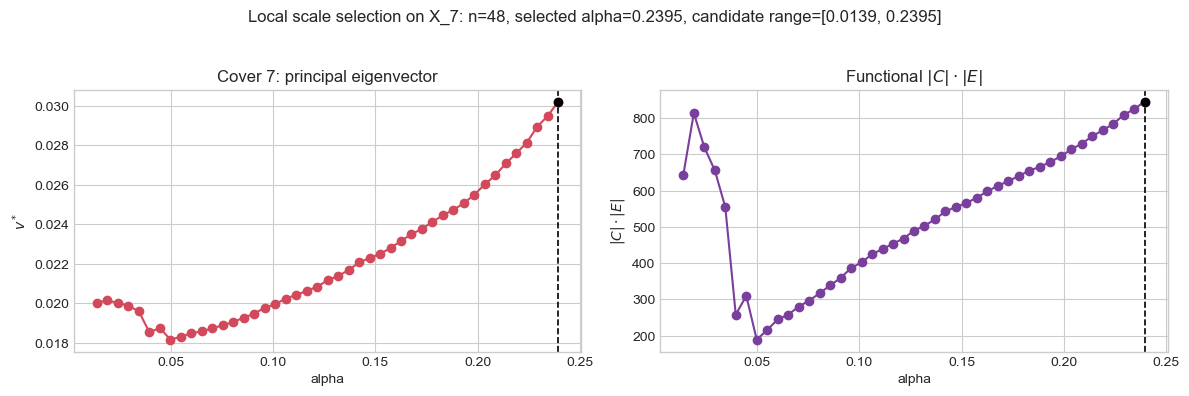

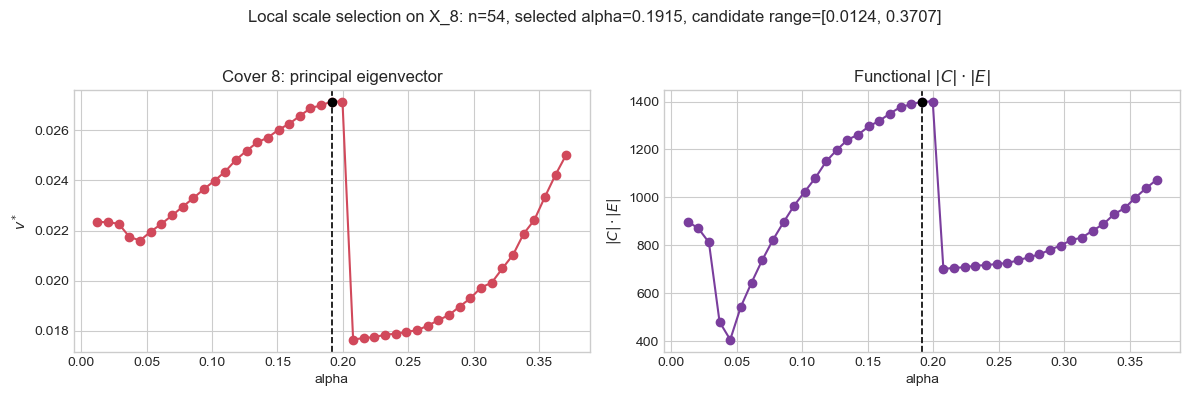

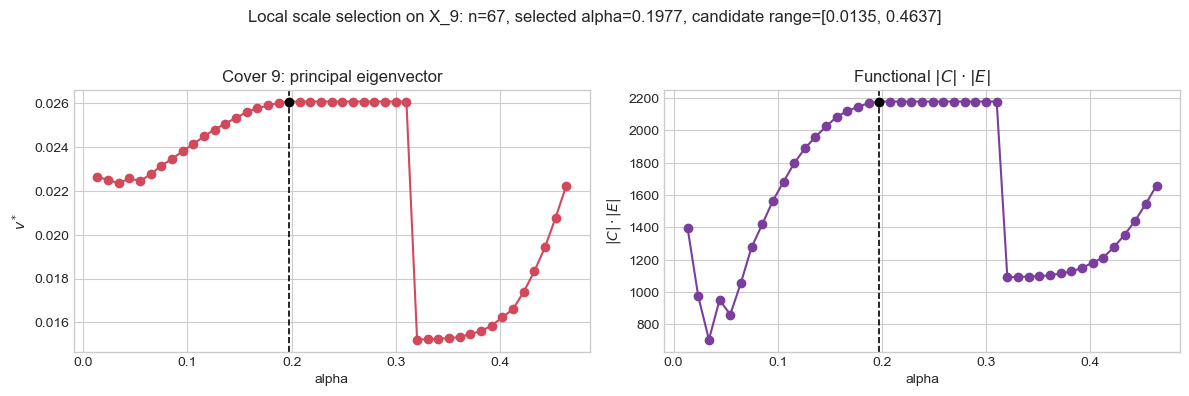

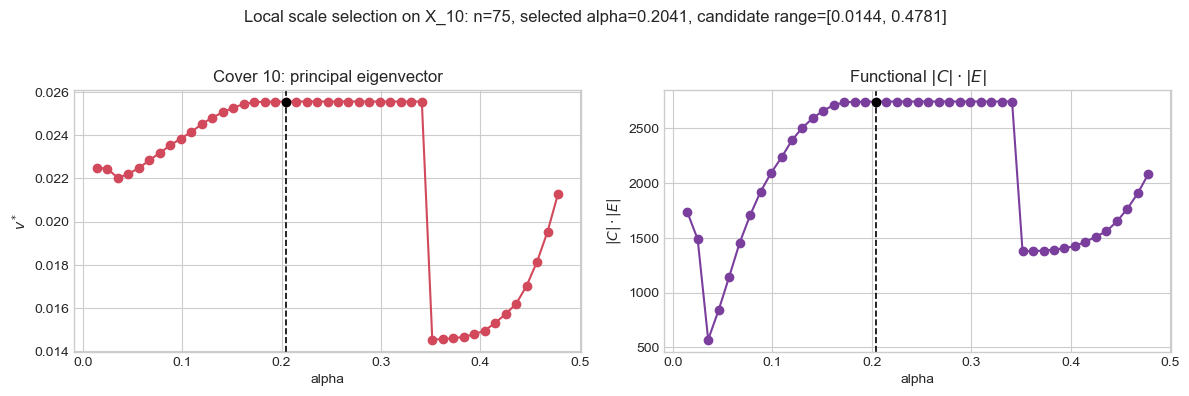

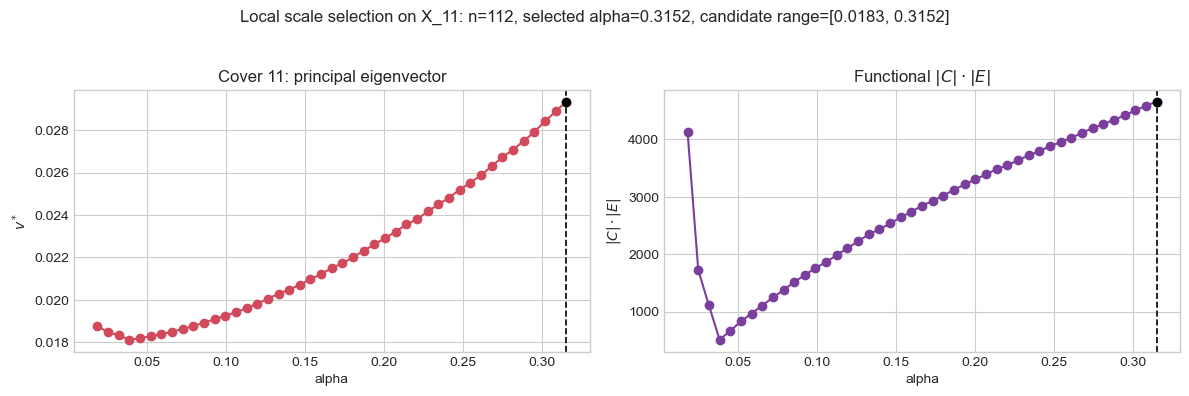

In [47]:
for j, result in enumerate(local_results):
    selected = result["selected_index"]
    selected_alpha = result["alpha"]

    fig, axes = plt.subplots(1, 2, figsize=(12.0, 3.8), sharex=True)

    axes[0].plot(result["alphas"], result["pf_vector"], marker="o", color="#d1495b")
    axes[0].axvline(selected_alpha, color="black", linestyle="--", linewidth=1.2)
    axes[0].scatter([selected_alpha], [result["pf_vector"][selected]], color="black", s=35, zorder=3)
    axes[0].set_title(f"Cover {j}: principal eigenvector")
    axes[0].set_xlabel("alpha")
    axes[0].set_ylabel(r"$v^*$")

    axes[1].plot(result["alphas"], result["functional"], marker="o", color="#7a3e9d")
    axes[1].axvline(selected_alpha, color="black", linestyle="--", linewidth=1.2)
    axes[1].scatter([selected_alpha], [result["functional"][selected]], color="black", s=35, zorder=3)
    axes[1].set_title(r"Functional $|C|\cdot |E|$")
    axes[1].set_xlabel("alpha")
    axes[1].set_ylabel(r"$|C|\cdot |E|$")

    fig.suptitle(
        f"Local scale selection on X_{j}: "
        f"n={len(result['members'])}, selected alpha={selected_alpha:.4f}, "
        f"candidate range=[{result['alpha_min']:.4f}, {result['alpha_max']:.4f}]",
        y=1.03,
    )
    plt.tight_layout()
    plt.show()

## 5. Assemble the multiscale alpha-neighboring graph

A pair of points is eligible only when both points occur in at least one common cover element. Its threshold is the maximum selected alpha among all common cover elements. The edge is inserted when the Euclidean distance is at most twice that threshold.

In [48]:
def build_multiscale_alpha_graph(points, local_results):
    D = pairwise_distances(points)
    graph = nx.Graph()
    graph.add_nodes_from(range(len(points)))

    best_alpha_for_pair = {}
    for result in local_results:
        alpha = result["alpha"]
        members = np.asarray(result["members"], dtype=int)
        for pos_i in range(len(members)):
            i = int(members[pos_i])
            for pos_j in range(pos_i + 1, len(members)):
                j = int(members[pos_j])
                pair = (i, int(j)) if i < int(j) else (int(j), i)
                if alpha > best_alpha_for_pair.get(pair, -np.inf):
                    best_alpha_for_pair[pair] = alpha

    for (i, j), alpha in best_alpha_for_pair.items():
        if D[i, j] <= 2.0 * alpha:
            graph.add_edge(i, j, weight=float(D[i, j]), alpha=float(alpha))
    return graph

G = build_multiscale_alpha_graph(X, local_results)
components = list(nx.connected_components(G))
print(f"Nodes: {G.number_of_nodes()}")
print(f"Edges: {G.number_of_edges()}")
print(f"Connected components: {len(components)}")
print(f"Largest component size: {max(map(len, components))}")
print(f"Isolated vertices: {sum(1 for node in G.nodes if G.degree[node] == 0)}")

Nodes: 480
Edges: 16413
Connected components: 1
Largest component size: 480
Isolated vertices: 0


In [49]:
def community_labels(graph):
    labels = np.full(graph.number_of_nodes(), -1, dtype=int)
    nontrivial_nodes = [node for node in graph.nodes if graph.degree[node] > 0]
    subgraph = graph.subgraph(nontrivial_nodes)

    if subgraph.number_of_edges() == 0:
        return labels, []

    communities = list(nx.algorithms.community.greedy_modularity_communities(subgraph))
    for label, community in enumerate(communities):
        for node in community:
            labels[node] = label
    return labels, communities

labels, communities = community_labels(G)
print(f"Detected communities among non-isolated vertices: {len(communities)}")
print("Community sizes:", sorted([len(c) for c in communities], reverse=True))

Detected communities among non-isolated vertices: 3
Community sizes: [166, 157, 157]


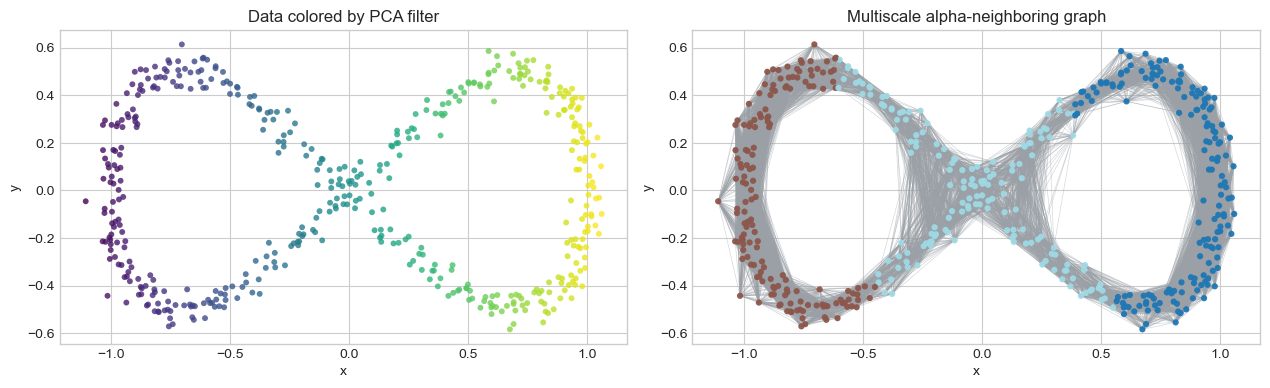

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.4))

axes[0].scatter(X[:, 0], X[:, 1], c=filter_values, cmap="viridis", s=18, alpha=0.8, linewidths=0)
axes[0].set_title("Data colored by PCA filter")
axes[0].set_aspect("equal")

for i, j in G.edges:
    axes[1].plot([X[i, 0], X[j, 0]], [X[i, 1], X[j, 1]], color="#9aa0a6", linewidth=0.45, alpha=0.45, zorder=1)
scatter = axes[1].scatter(X[:, 0], X[:, 1], c=labels, cmap="tab20", s=20, alpha=0.95, linewidths=0, zorder=2)
axes[1].set_title("Multiscale alpha-neighboring graph")
axes[1].set_aspect("equal")

for ax in axes:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()

## 6. Poster-style rendering

This cell reproduces the visual style of `eight_proper.png`: transparent black graph edges, small colored vertices, no axes, equal aspect ratio, and a high-resolution PNG export.

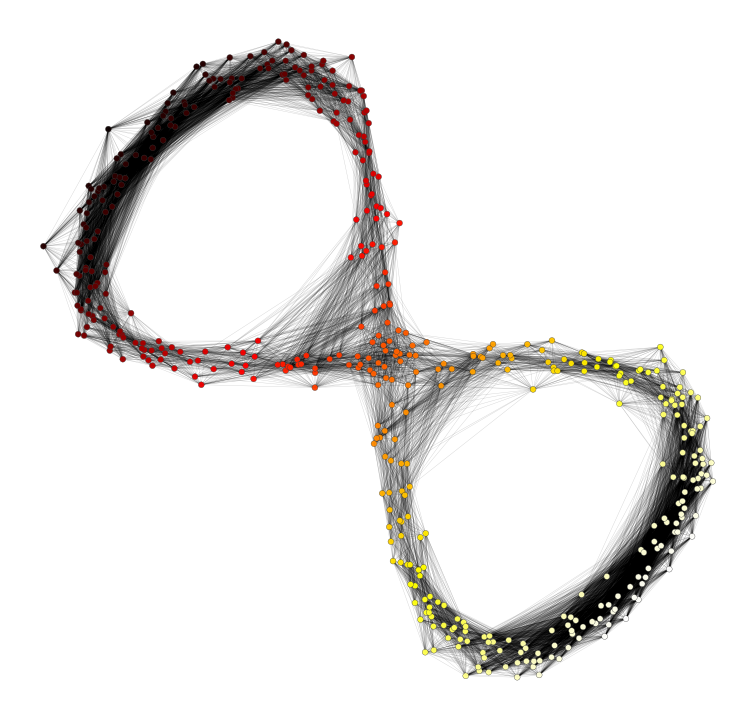

Saved poster-style graph to /Users/iljasukhanov/MASTERARBEIT/Images/synthetic_eight_malphaN_poster_style.png


In [51]:
from pathlib import Path

def rotate_points(points, degrees=-42):
    theta = np.deg2rad(degrees)
    rotation = np.array([
        [np.cos(theta), -np.sin(theta)],
        [np.sin(theta), np.cos(theta)],
    ])
    centered = points - points.mean(axis=0, keepdims=True)
    return centered @ rotation.T

poster_positions = rotate_points(X, degrees=-42)
poster_colors = filter_values
image_dir = Path("Images") if Path("Images").exists() else Path("../Images")
output_path = image_dir / "synthetic_eight_malphaN_poster_style.png"
output_path.parent.mkdir(parents=True, exist_ok=True)

def save_poster_style_graph(graph, output_path, title=None):
    fig, ax = plt.subplots(figsize=(9.5, 9.5), facecolor="white")
    ax.set_facecolor("white")

    for i, j in graph.edges:
        ax.plot(
            [poster_positions[i, 0], poster_positions[j, 0]],
            [poster_positions[i, 1], poster_positions[j, 1]],
            color="black",
            linewidth=0.28,
            alpha=0.18,
            zorder=1,
        )

    ax.scatter(
        poster_positions[:, 0],
        poster_positions[:, 1],
        c=poster_colors,
        cmap="hot",
        s=18,
        edgecolors="#3a3a3a",
        linewidths=0.25,
        alpha=0.98,
        zorder=2,
    )

    if title is not None:
        ax.set_title(title)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.margins(0.05)
    fig.savefig(output_path, dpi=300, bbox_inches="tight", pad_inches=0.08)
    plt.show()
    return output_path

save_poster_style_graph(G, output_path)
print(f"Saved poster-style graph to {output_path.resolve()}")

## 7. Random local thresholds as a contrast

The poster report contrasts the spectral construction with random local thresholds. The next cell keeps the same cover but chooses a random candidate alpha independently in every cover element before assembling the graph.

Spectral graph
  edges=16413, components=1, isolated=0
Random-threshold graph
  edges=9942, components=17, isolated=5


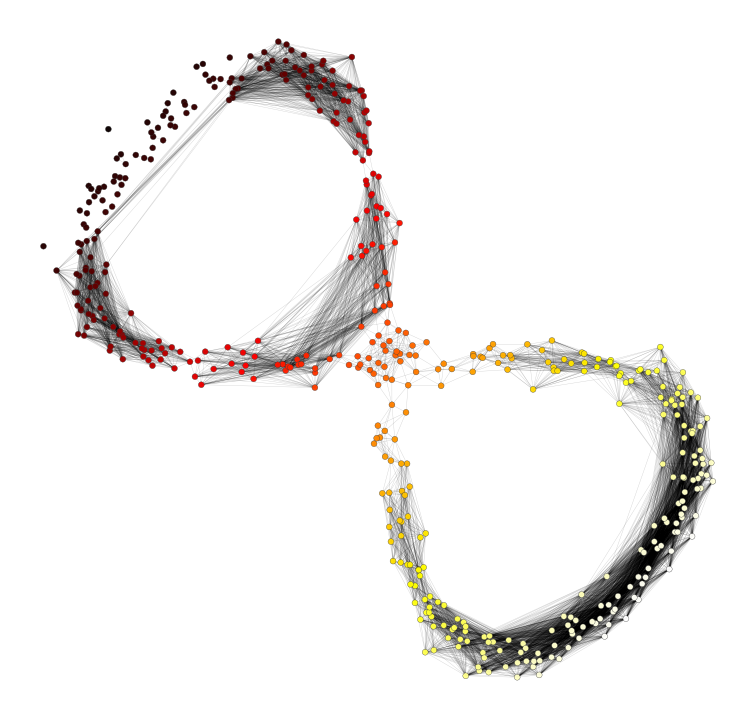

Saved random-threshold poster-style graph to /Users/iljasukhanov/MASTERARBEIT/Images/synthetic_eight_random_thresholds_poster_style.png


In [52]:
random_threshold_rng = np.random.default_rng(123)
randomized_results = []
for result in local_results:
    copied = dict(result)
    copied["alpha"] = float(random_threshold_rng.choice(result["alphas"]))
    randomized_results.append(copied)

G_random = build_multiscale_alpha_graph(X, randomized_results)

print("Spectral graph")
print(f"  edges={G.number_of_edges()}, components={nx.number_connected_components(G)}, isolated={sum(1 for n in G.nodes if G.degree[n] == 0)}")
print("Random-threshold graph")
print(f"  edges={G_random.number_of_edges()}, components={nx.number_connected_components(G_random)}, isolated={sum(1 for n in G_random.nodes if G_random.degree[n] == 0)}")

random_output_path = image_dir / "synthetic_eight_random_thresholds_poster_style.png"
save_poster_style_graph(G_random, random_output_path)
print(f"Saved random-threshold poster-style graph to {random_output_path.resolve()}")

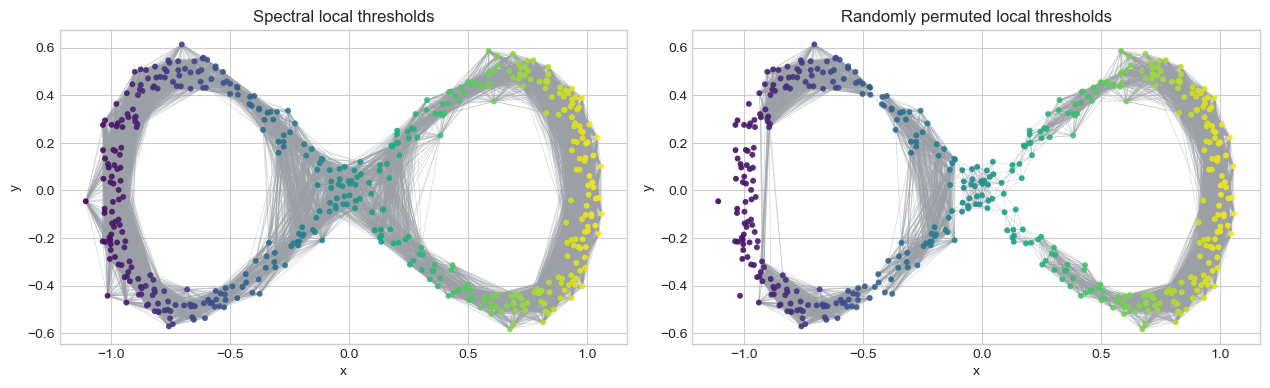

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.4))

for ax, graph, title in [
    (axes[0], G, "Spectral local thresholds"),
    (axes[1], G_random, "Randomly permuted local thresholds"),
]:
    for i, j in graph.edges:
        ax.plot([X[i, 0], X[j, 0]], [X[i, 1], X[j, 1]], color="#9aa0a6", linewidth=0.45, alpha=0.45, zorder=1)
    ax.scatter(X[:, 0], X[:, 1], c=filter_values, cmap="viridis", s=18, alpha=0.9, linewidths=0, zorder=2)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()

## Notes

The graph should preserve the two-loop structure while avoiding a single global threshold. The important object for the local scale choice is the non-monotone profile `|C|*|E|`: at very small scales there are many connected components but few edges, while at large scales there are many edges but fewer components. The Perron-Frobenius vector of the scale-similarity matrix highlights the scale where this tradeoff is most prominent in the local filtration.